In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, TensorDataset
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc
import seaborn as sns

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

print(torch.__version__)

cuda
2.13.0+cu130


In [6]:
torch.manual_seed(42) # 42라는 숫자는 아무의미 없음. 재현을 위한것임으로 일정하게만 쓰면 됨
np.random.seed(42)

In [ ]:
def perceptron_and(x1, x2):
	w = torch.tensor([0.5, 0.5])
	b = torch.tensor(-0.7)
	x = torch.tensor([x1, x2],
					 dtype = torch.float32)
	output = torch.dot(w, x) + b
	return 1 if output >= 0 else 0

print(perceptron_and(0, 0))
print(perceptron_and(0, 1))
print(perceptron_and(1, 0))
print(perceptron_and(1, 1))

0
0
0
1


In [ ]:
class SimpleNN(nn.Module):
	def __init__(self):
		super(SimpleNN, self).__init__()
		# nn.Linear(들어오는 개수, 나가는 개수)
		self.fc1 = nn.Linear(2, 3)
		self.fc2 = nn.Linear(3, 1)

	def forward(self, x):
		x = torch.relu(self.fc1(x))
		x = torch.sigmoid(self.fc2(x))
		return x

model = SimpleNN()
sample_input = torch.tensor([1.0, 2.0])
output = model(sample_input)
print(output)

tensor([0.6693], grad_fn=<SigmoidBackward0>)


In [12]:
class SimpleNN_Full(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(SimpleNN_Full, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        return x

model = SimpleNN_Full(input_size = 10,
                      hidden_size = 20,
                      output_size = 1)
print(model)

for param in model.parameters():
    print(param.shape)

SimpleNN_Full(
  (fc1): Linear(in_features=10, out_features=20, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=20, out_features=1, bias=True)
)
torch.Size([20, 10])
torch.Size([20])
torch.Size([1, 20])
torch.Size([1])


In [13]:
X_train = torch.randn(100, 10)
y_train = torch.randn(100, 1)
dataset = TensorDataset(X_train, y_train)

dataloader = DataLoader(dataset,
                        batch_size = 32,
                        shuffle = True)

In [ ]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr = 0.001)

for epoch in range(10):
    for batch in dataloader:
        inputs, targets = batch
        optimizer.zero_grad()                           
        outputs = model(inputs)                     
        loss = criterion(outputs, targets)                      
        loss.backward()                     
        optimizer.step()                        
    print(epoch + 1, loss.item())

1 0.7551046013832092
2 1.6261229515075684
3 1.5009170770645142
4 0.571897029876709
5 0.7857438325881958
6 0.7620089650154114
7 1.4120872020721436
8 1.366011619567871
9 1.9716987609863281
10 0.2729737162590027


In [15]:
torch.save(model.state_dict(), 'model.pth')
model = SimpleNN_Full(input_size = 10,
                      hidden_size = 20,
                      output_size = 1)
model.load_state_dict(torch.load('model.pth'))

<All keys matched successfully>

In [17]:
def check_nan_loss(loss, optimizer):
    if torch.isnan(loss).any():
        print('Loss에 nan이 포함되어 있음')

        for param_group in optimizer.param_groups:
            param_group['lr'] *= 0.1
        return True

    return False

sample_loss = torch.tensor(float('nan'))
nan_detected = check_nan_loss(sample_loss, optimizer)
print(nan_detected)

Loss에 nan이 포함되어 있음
True


In [18]:
transform = transforms.Compose([transforms.RandomHorizontalFlip(),
                                transforms.RandomRotation(10),
                                transforms.ToTensor()])

In [19]:
# MNIST
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.1307, ),        # 평균
                                                     (0.3081, ))       # 표준편차
                                                     ])

train_dataset = torchvision.datasets.MNIST(root = './data',
                                           train = True,
                                           transform = transform,
                                           download = True)

test_dataset = torchvision.datasets.MNIST(root = './data',
                                           train = False,
                                           transform = transform,
                                           download = True)

100%|██████████| 9.91M/9.91M [00:05<00:00, 1.81MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 145kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 1.71MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 4.54MB/s]


In [20]:
train_loader = DataLoader(dataset = train_dataset,
                          batch_size = 64,
                          shuffle = True)
test_loader = DataLoader(dataset = test_dataset,
                          batch_size = 1000,
                          shuffle = False)

print(len(train_loader))
print(len(test_loader))

938
10


In [25]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(-1, 28 * 28)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [28]:
model = MLP().to(device)

# model = MLP()

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(),
                       lr = 0.001)

In [29]:
for epoch in range(10):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        data, target = data.to(device), target.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()
    print(epoch +1, loss.item())

1 0.19192785024642944
2 0.028475061058998108
3 0.01734735257923603
4 0.017894180491566658
5 0.0941566675901413
6 0.0043176086619496346
7 0.052281830459833145
8 0.000866532267536968
9 0.018864279612898827
10 0.012471890076994896


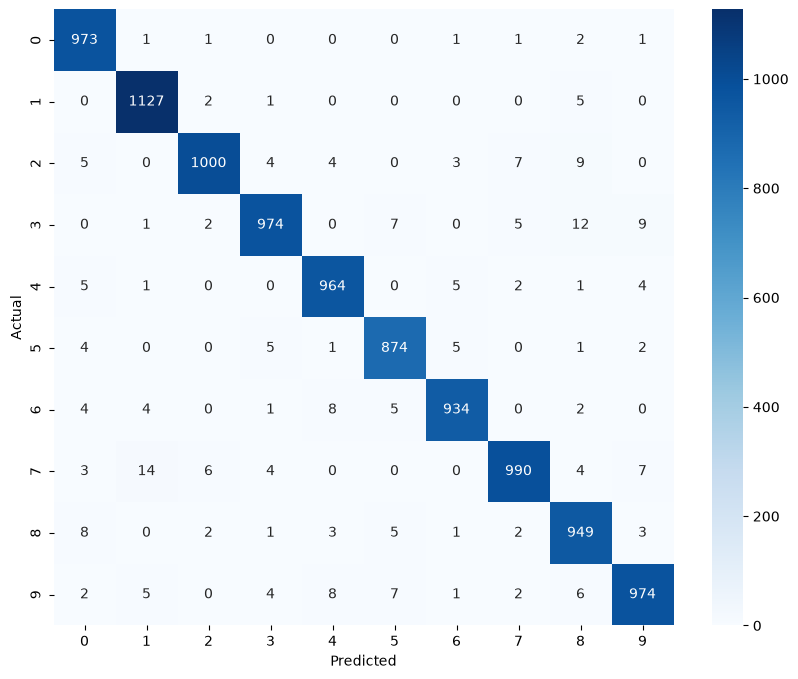

In [31]:
model.eval()
all_targets = []
all_preds = []

with torch.no_grad():
    for data, target in test_loader:
        data, target = data.to(device), target.to(device)
        output = model(data)
        _, predicted = torch.max(output.data, 1)
        all_targets.extend(target.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())
targets = np.array(all_targets)
preds = np.array(all_preds)

cm_mnist = confusion_matrix(targets, preds)
plt.figure(figsize = (10, 8))
sns.heatmap(cm_mnist,
            annot = True,
            fmt = 'd',
            cmap = 'Blues',
            xticklabels = range(10),
            yticklabels = range(10))
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

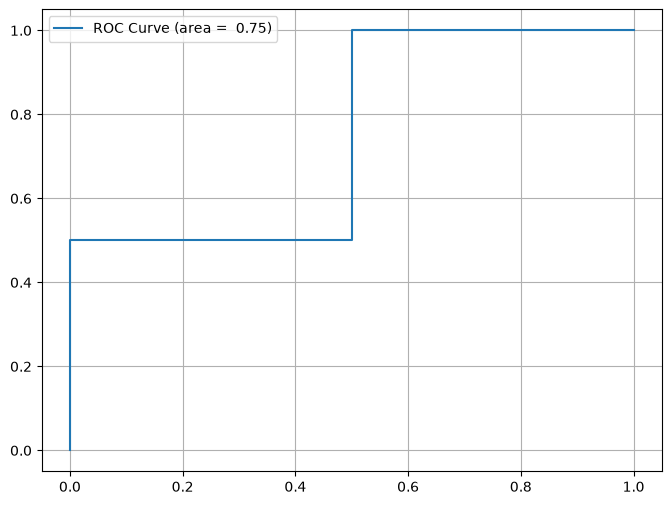

In [33]:
y_scores = np.array([0.1, 0.4, 0.35, 0.8])
y_test = np.array([0, 0, 1, 1])

fpr, tpr, _  = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)

plt.figure(figsize = (8, 6))
plt.plot(fpr, tpr, label = f'ROC Curve (area = {roc_auc: .2f})')
plt.legend()
plt.grid(True)
plt.show()

In [34]:
from torch.optim.lr_scheduler import ReduceLROnPlateau

scheduler = ReduceLROnPlateau(optimizer,
                             mode = 'min',
                             patience = 3,
                             factor = 0.1)

for epoch in range(50):
    # train_one_epoch(model, train_loader, ...)
    # val_loss = evaluate(model, val_loader)
    # scheduler.step(val_loss)
    train_loss = 0.2 * (50 - epoch)
    scheduler.step(train_loss)

In [ ]:
# 드랍아웃
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(28*28, 128)
        self.dropout1 = nn.Dropout(0.50)
        #self.bn1 = nn.BatchNorm1d(128)
        self.fc2 = nn.Linear(128, 64)
        self.dropout2 = nn.Dropout(0.50)
        #self.bn2 = nn.BatchNorm1d(64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        x = x.view(-1, 28*28)
        #x = F.relu(self.bn1(self.fc1(x)))
        x = F.relu(self.dropout1(self.fc1(x)))
        #x = F.relu(self.bn2(self.fc2(x)))
        x = F.relu(self.dropout2(self.fc2(x)))
        x = self.fc3(x)
        return x